# SINEX — station coordinates depend on epoch


A SINEX `SOLUTION/ESTIMATE` block can provide ECEF position $(X_0,Y_0,Z_0)$ in **metres**, velocity $(V_X,V_Y,V_Z)$ in **metres per year**, and a **reference epoch** $t_0$. For a simple constant-velocity model,

$$\mathbf r(t) = \mathbf r_0 + \mathbf v(t-t_0),\qquad \Delta t \text{ in Julian years of 365.25 days}$$

Station coordinates also depend on the **reference frame**, antenna monument and solution validity period. In real processing, earthquakes, post-seismic motion and seasonal displacement may require more elaborate models.

In [2]:
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from dsoclasses.sinex.sinex import Sinex, extract_sinex_coordinates
from dsoclasses.time.pyattotime import to_attoseconds
from os.path import join

data_path = "../../data"
snx_path = join(data_path, "dpod2020_041.snx")

snx = Sinex(snx_path)
records = snx.solution_estimate(['DIOB'], append_solution_epoch_info=True)
print('SINEX format version:', snx.version)
print('Reference epoch:', records[0]['epoch'])
for row in records:
    print(f"{row['parameter_type']:>4s}: {row['value']:>14.6f} {row['unit']}")
# assert len(records) == 6

SINEX format version: 2.02
Reference epoch: 2000-01-01 00:00:00
STAX: 4595212.447758 m
STAY: 2039473.642044 m
STAZ: 3912617.947242 m
VELX:       0.003656 m/y
VELY:       0.010290 m/y
VELZ:      -0.009408 m/y


## 1. Extrapolate the published position

Let's compare the station at its reference epoch with **2.5 years later**, including half a day. The helper `extract_sinex_coordinates()` returns the propagated ECEF position. It only works with the solution's declared validity interval and assumes linear motion.

In [6]:
reference_epoch = datetime(2024, 1, 1)
target_epoch = datetime(2026, 7, 1, 12)

r0 = extract_sinex_coordinates(snx_path, ['DIOB'], reference_epoch)['DIOB']
r1 = extract_sinex_coordinates(snx_path, ['DIOB'], target_epoch)['DIOB']
xyz0 = np.array([r0[axis] for axis in 'XYZ'])
xyz1 = np.array([r1[axis] for axis in 'XYZ'])
shift = xyz1 - xyz0

years = (to_attoseconds(target_epoch)-to_attoseconds(reference_epoch))/(365.25*86400*1e18)
print(f'Elapsed time: {years:.8f} Julian years')
print('Coordinate shift [cm]:', np.round(100*shift, 2))
print(f'Total displacement: {np.linalg.norm(shift)*100:.2f} cm')

# velocity = np.array([next(r['value'] for r in records if r['parameter_type'] == 'VEL'+axis)
#                      for axis in 'XYZ'])
# assert np.allclose(shift, velocity*years, atol=1e-8)

Elapsed time: 2.49828884 Julian years
Coordinate shift [cm]: [ 0.91  2.57 -2.35]
Total displacement: 3.60 cm


## 2. Why this matters for positioning

A station drifting by a few centimetres per year may be displaced by **decimetres** from an old reference position. This matters when evaluating GNSS results in a terrestrial reference frame. A SINEX position is not automatically the **antenna reference point (ARP)**; possible site eccentricities and offsets are separate.

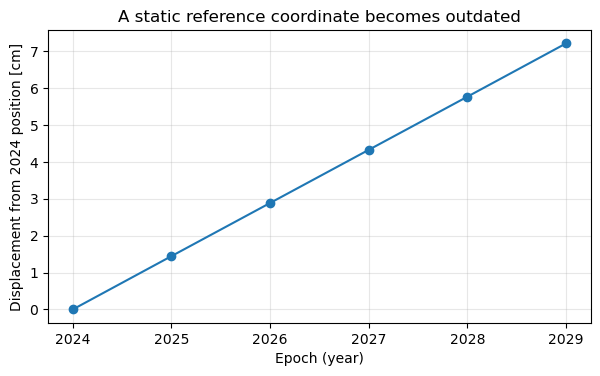

In [9]:
epochs = [datetime(year, 1, 1) for year in range(2024, 2030)]
shifts_cm = []
for date in epochs:
    estimated = extract_sinex_coordinates(snx_path, ['DIOB'], date)['DIOB']
    vector = np.array([estimated[k] for k in 'XYZ'])
    shifts_cm.append(100*np.linalg.norm(vector - xyz0))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot([d.year for d in epochs], shifts_cm, 'o-')
ax.set(xlabel='Epoch (year)', ylabel='Displacement from 2024 position [cm]',
       title='A static reference coordinate becomes outdated')
ax.grid(alpha=0.3)
plt.show()

### Remember

- `Sinex(...).solution_estimate(...)` reads positions and velocities.
- `extract_sinex_coordinates(path, [site], epoch)` propagates to a requested epoch.
- Frame consistency, epoch validity and discontinuities come **before** evaluating centimetre-level positioning results.

Reference: [IGS SINEX format and standards](https://igs.org/formats-and-standards/).